In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# SETUP

In [2]:
#
m = 1.0
mu = 5.0
k = 500.0

#
delta = mu/ (2*m)
omega0 = np.sqrt(k)
omega = np.sqrt(omega0**2 - delta**2)

#
phi = np.arctan(-delta / omega)
A = 1 / (2 * np.cos(phi))


def x_exact(t):
    #closed form solution
    return np.exp(-delta*t) * 2 * A * np.cos(phi + omega * t)

#
t_plot = np.linspace(0,1,500)

In [3]:
n_data = 10

#Equally spaced points on [0,0.5] (dropping two endpoints)
t_data = np.linspace(0, 0.5, n_data + 2)[1:-1]
x_data = x_exact(t_data)

print("data", t_data)

data [0.04545455 0.09090909 0.13636364 0.18181818 0.22727273 0.27272727
 0.31818182 0.36363636 0.40909091 0.45454545]


In [4]:
#Shallow network: 1 hidden leayer, tanh activation, linear output

class ShallowNet(nn.Module):
    def __init__(self, n_hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, n_hidden),
            nn.Tanh(),
            nn.Linear(n_hidden, 1),
        )

    def forward(self, t):
        return self.net(t)

def init_weights(n_hidden, seed):
    #
    torch.manual_seed(seed)
    net = ShallowNet(n_hidden)
    w1 = net.net[0].weight.detach().numpy().ravel().astype(np.float64)
    b1 = net.net[0].bias.detach().numpy().ravel().astype(np.float64)
    w2 = net.net[2].weight.detach().numpy().ravel().astype(np.float64)
    b2 = float(net.net[2].bias.detach().numpy()[0])
    return w1, b1, w2, b2

# Task 2.1

x_exact(0) = 1.0 (should be 1)


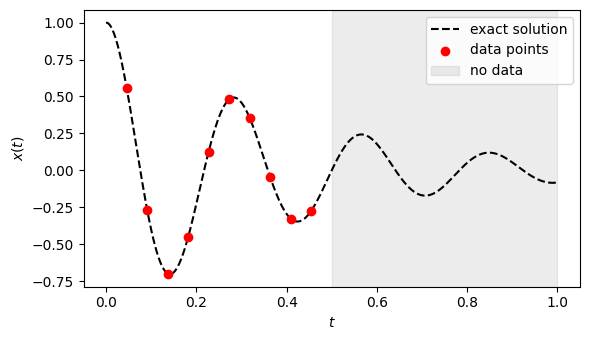

In [5]:
print("x_exact(0) =", x_exact(0.0), "(should be 1)")

plt.figure(figsize=(6, 3.5))
plt.plot(t_plot, x_exact(t_plot), "k--", label="exact solution")
plt.scatter(t_data, x_data, color="red", zorder=3, label="data points")
plt.axvspan(0.5, 1.0, color="gray", alpha=0.15, label="no data")
plt.xlabel("$t$")
plt.ylabel("$x(t)$")
plt.legend()
plt.tight_layout()
plt.show()

# Task 2.2

In [6]:
# parameters
n_hidden_22 = 32       # choose  (number of hidden neurons)
lr_22 = 1e-3           # choose  (learning rate)
n_steps_22 = 5000      # choose  (number of training steps)
seed_22 = 0            # choose  (random seed for the initial weights)

In [7]:
torch.manual_seed(seed_22)

t_train = torch.tensor(t_data, dtype=torch.float64).reshape(-1,1)
x_train = torch.tensor(x_data, dtype=torch.float64).reshape(-1,1)

model_22 = ShallowNet(n_hidden_22).double()
optimizer_22 = torch.optim.Adam(model_22.parameters(), lr = lr_22)
mse = nn.MSELoss()

losses_22 = []
for step in range(n_steps_22):
    optimizer_22.zero_grad()
    loss = mse(model_22(t_train), x_train)
    loss.backward()
    optimizer_22.step()
    losses_22.append(loss.item())

print("finala data loss:", losses_22[-1])


finala data loss: 0.007447995956768806


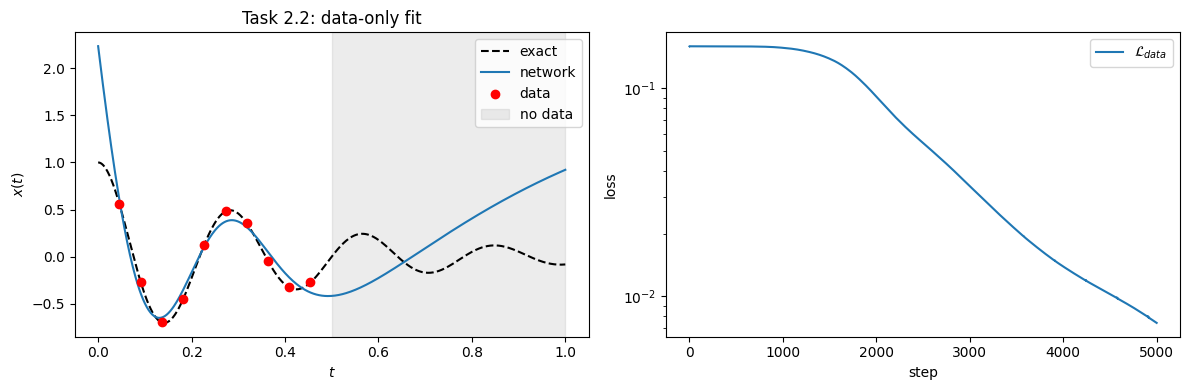

In [8]:
#inference 

with torch.no_grad():
    t_test = torch.tensor(t_plot, dtype=torch.float64).reshape(-1, 1)
    x_pred_22 = model_22(t_test).numpy().ravel()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(t_plot, x_exact(t_plot), "k--", label="exact")
ax[0].plot(t_plot, x_pred_22, label="network")
ax[0].scatter(t_data, x_data, color="red", zorder=3, label="data")
ax[0].axvspan(0.5, 1.0, color="gray", alpha=0.15, label="no data")
ax[0].set_xlabel("$t$")
ax[0].set_ylabel("$x(t)$")
ax[0].set_title("Task 2.2: data-only fit")
ax[0].legend()

ax[1].semilogy(losses_22, label=r"$\mathcal{L}_{data}$")
ax[1].set_xlabel("step")
ax[1].set_ylabel("loss")
ax[1].legend()

plt.tight_layout()
plt.show()

# Task 2.3

In [9]:
# ---- parameters: change these ----
n_colloc = 50          
t_colloc_max = 1.0     # collocation points are placed on [0, t_colloc_max]

t_phys = np.linspace(0, t_colloc_max, n_colloc)

### Network output and time derivatives

In [10]:
def hidden_layer(t, w1, b1):
    t = np.asarray(t, dtype=np.float64).reshape(-1,1)
    z = t * w1 + b1
    h = np.tanh(z)
    s = 1 - h**2            # sech^2(z) = derivative of tanh
    return h, s

def network_output(t,w1, b1, w2, b2):
    h, s = hidden_layer(t, w1, b1)
    return h @ w2 + b2

def network_dt(t, w1, b1, w2, b2):
    h, s = hidden_layer(t, w1, b1)
    return s @(w2 * w1)

def network_dtt(t, w1, b1, w2, b2):
    h, s = hidden_layer(t, w1, b1)
    return (-2 * h * s) @ (w2 * w1**2)


### The three loss terms

In [11]:
def physics_residual(t, w1, b1, w2, b2):
    N = network_output(t, w1, b1, w2, b2)
    dN = network_dt(t, w1, b1, w2, b2)
    ddN = network_dtt(t, w1, b1, w2, b2)
    return ddN + mu * dN + k * N

def loss_terms(w1, b1, w2, b2, t_data, x_data, t_phys):
    # L_data = 1/N_d sum_i (N(t_i) - x_i)^2
    L_data = np.mean((network_output(t_data, w1, b1, w2, b2) - x_data)**2)

    # L_phys = 1/N_c sum_c r(t_c)^2                         
    r = physics_residual(t_phys, w1, b1, w2, b2)
    L_phys = np.mean(r**2)

    # L_IC = (N(0) - 1)^2 + (N'(0) - 0)^2                  
    N0 = network_output(0.0, w1, b1, w2, b2)[0]
    dN0 = network_dt(0.0, w1, b1, w2, b2)[0]
    L_ic = (N0 - 1)**2 + dN0**2

    return L_data, L_phys, L_ic


def total_loss(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic):
    # L = L_data + lam_phys L_phys + lam_ic L_IC       
    L_data, L_phys, L_ic = loss_terms(w1, b1, w2, b2, t_data, x_data, t_phys)
    return L_data + lam_phys * L_phys + lam_ic * L_ic


### Derivatives of $N$, $N'$, $N''$ with respect to each parameter (inlcuding biases)

In [12]:
def sensitivities_W1(t, w1, b1, w2):
    # derivatives w.r.t. W1_j
    h, s = hidden_layer(t, w1, b1)
    t = np.asarray(t, dtype=np.float64).reshape(-1, 1)
    dN_dW1   = w2 * t * s                                              
    dN1_dW1  = w2 * s * (1 - 2 * t * w1 * h)                           
    dN2_dW1  = -2 * w2 * w1 * s * (2 * h + t * w1 * (1 - 3 * h**2))    
    return dN_dW1, dN1_dW1, dN2_dW1


def sensitivities_W2(t, w1, b1, w2):
    # derivatives w.r.t. W2_j                     
    h, s = hidden_layer(t, w1, b1)
    dN_dW2   = h
    dN1_dW2  = w1 * s
    dN2_dW2  = -2 * w1**2 * h * s
    return dN_dW2, dN1_dW2, dN2_dW2


def sensitivities_b1(t, w1, b1, w2):
    # derivatives w.r.t. b1_j     
    h, s = hidden_layer(t, w1, b1)
    dN_db1   = w2 * s
    dN1_db1  = -2 * w2 * w1 * h * s
    dN2_db1  = -2 * w2 * w1**2 * s * (1 - 3 * h**2)
    return dN_db1, dN1_db1, dN2_db1


def sensitivities_b2(t, w1, b1, w2):
    # derivatives w.r.t. b2       
    T = len(np.atleast_1d(t))
    dN_db2   = np.ones((T, 1))
    dN1_db2  = np.zeros((T, 1))
    dN2_db2  = np.zeros((T, 1))
    return dN_db2, dN1_db2, dN2_db2

### Chain rule through the loss: $\partial\mathcal{L}/\partial\theta$

All four gradients have the same structure (only the sensitivities above change)


$$\frac{\partial \mathcal{L}}{\partial\theta} = \frac{2}{N_d}\sum_i (N(t_i)-x_i)\frac{\partial N(t_i)}{\partial\theta}
+ \lambda_{phys}\frac{2}{N_c}\sum_c r(t_c)\left(\frac{\partial N''}{\partial\theta}+\mu\frac{\partial N'}{\partial\theta}+k\frac{\partial N}{\partial\theta}\right)(t_c)
+ \lambda_{IC}\left(2(N(0)-1)\frac{\partial N(0)}{\partial\theta} + 2N'(0)\frac{\partial N'(0)}{\partial\theta}\right)$$

In [13]:
def chain_rule_gradient(sensitivity_function, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic):
    #data term
    dN_d, dN1_d, dN2_d = sensitivity_function(t_data, w1, b1, w2)
    error_data = network_output(t_data, w1, b1, w2, b2) - x_data          
    grad_data = 2 / len(t_data) * (error_data @ dN_d)    

    #physics term
    dN_p, dN1_p, dN2_p = sensitivity_function(t_phys, w1, b1, w2)
    r = physics_residual(t_phys, w1, b1, w2, b2)                           
    dr_dtheta = dN2_p + mu * dN1_p + k * dN_p                              
    grad_phys = 2 / len(t_phys) * (r @ dr_dtheta)

    #IC term
    dN_0, dN1_0, dN2_0 = sensitivity_function(0.0, w1, b1, w2)
    N0 = network_output(0.0, w1, b1, w2, b2)[0]
    dN0 = network_dt(0.0, w1, b1, w2, b2)[0]
    grad_ic = 2 * (N0- 1) * dN_0[0] + 2 * dN0 * dN1_0[0]

    return grad_data + lam_phys * grad_phys + lam_ic * grad_ic


# FUCNTIONS THAT GIVE RESPECTIVE DERIVATIVE 
def grad_W1(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic):
    # dL/dW1                                                   
    return chain_rule_gradient(sensitivities_W1, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)


def grad_W2(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic):
    # dL/dW2                                                    
    return chain_rule_gradient(sensitivities_W2, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)


def grad_b1(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic):
    # dL/db1                   
    return chain_rule_gradient(sensitivities_b1, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)


def grad_b2(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic):
    # dL/db2                 
    g = chain_rule_gradient(sensitivities_b2, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
    return float(g[0])

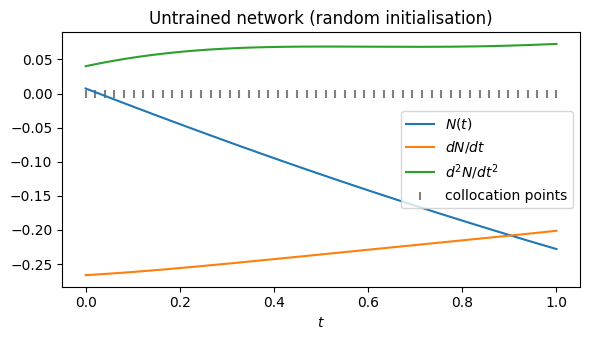

In [14]:
# Plot: what the (still untrained) network and its time derivatives look like for one random initialisation.
w1_demo, b1_demo, w2_demo, b2_demo = init_weights(n_hidden=32, seed=0)

plt.figure(figsize=(6, 3.5))
plt.plot(t_plot, network_output(t_plot, w1_demo, b1_demo, w2_demo, b2_demo), label="$N(t)$")
plt.plot(t_plot, network_dt(t_plot, w1_demo, b1_demo, w2_demo, b2_demo), label="$dN/dt$")
plt.plot(t_plot, network_dtt(t_plot, w1_demo, b1_demo, w2_demo, b2_demo), label="$d^2N/dt^2$")
plt.scatter(t_phys, np.zeros_like(t_phys), marker="|", color="gray", label="collocation points")
plt.xlabel("$t$")
plt.title("Untrained network (random initialisation)")
plt.legend()
plt.tight_layout()
plt.show()

# Task 2.4

In [15]:
# ---- parameters: change these ----
n_hidden_24 = 32       # (number of hidden neurons)
seed_24 = 1            # (random seed for the initial weights)
lam_phys_24 = 1.0      # (any value works for the check; non-zero so every term is tested)
lam_ic_24 = 1.0        
eps = 1e-5             # step size

In [16]:
def finite_difference_gradient(which, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic, eps):

    if which == "b2":
        L_plus = total_loss(w1, b1, w2, b2 + eps, t_data, x_data, t_phys, lam_phys, lam_ic)
        L_minus = total_loss(w1, b1, w2, b2 - eps, t_data, x_data, t_phys, lam_phys, lam_ic)
        return (L_plus - L_minus)/ (2 * eps)

    if which == "W1":
        theta = w1
    elif which == "W2":
        theta = w2
    elif which == "b1":
        theta = b1

    grad = np.zeros_like(theta)
    for j in range(len(theta)):
        theta_plus = theta.copy()
        theta_plus[j]= theta_plus[j] + eps
        theta_minus = theta.copy()
        theta_minus[j] = theta_minus[j] - eps

        if which == "W1":
            L_plus = total_loss(theta_plus, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
            L_minus = total_loss(theta_minus, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
        elif which == "W2":
            L_plus = total_loss(w1, b1, theta_plus, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
            L_minus = total_loss(w1, b1, theta_minus, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
        elif which == "b1":
            L_plus = total_loss(w1, theta_plus, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
            L_minus = total_loss(w1, theta_minus, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)   

        grad[j] = (L_plus - L_minus) / (2 * eps)

    return grad


def relative_error(a, b):
    # ||a - b|| / max(||a||, ||b||) (using this beacause we dont actually have a ground truth)
    a = np.atleast_1d(a)
    b = np.atleast_1d(b)

    return np.linalg.norm(a - b) / max(np.linalg.norm(a), np.linalg.norm(b))


In [17]:
#random initial net
w1, b1, w2, b2 = init_weights(n_hidden_24, seed_24)

#compute the gradients based on these random weights
analytical = {
    "W1": grad_W1(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys_24, lam_ic_24),
    "W2": grad_W2(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys_24, lam_ic_24),
    "b1": grad_b1(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys_24, lam_ic_24),   
    "b2": grad_b2(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys_24, lam_ic_24),   
}

numerical = {}
for name in ["W1", "W2", "b1", "b2"]:
    numerical[name] = finite_difference_gradient(name, w1, b1, w2, b2, t_data, x_data, t_phys,
                                                 lam_phys_24, lam_ic_24, eps)


# we check relative error is less than 1e-6 as for float 64 this number is a guideline for accuracy
# basically if its satisfied then the hand derived derivatives are coded the correct way 
print(f"{'param':6s} {'max abs diff':>14s} {'relative error':>16s}")
for name in ["W1", "W2", "b1", "b2"]:
    max_abs = np.max(np.abs(np.atleast_1d(analytical[name]) - np.atleast_1d(numerical[name])))
    rel = relative_error(analytical[name], numerical[name])
    status = "OK" if rel < 1e-6 else "CHECK!"
    print(f"{name:6s} {max_abs:14.3e} {rel:16.3e}   {status}")

param    max abs diff   relative error
W1          1.310e-07        4.611e-11   OK
W2          4.424e-08        8.656e-13   OK
b1          4.254e-07        6.771e-11   OK
b2          7.465e-09        2.478e-13   OK


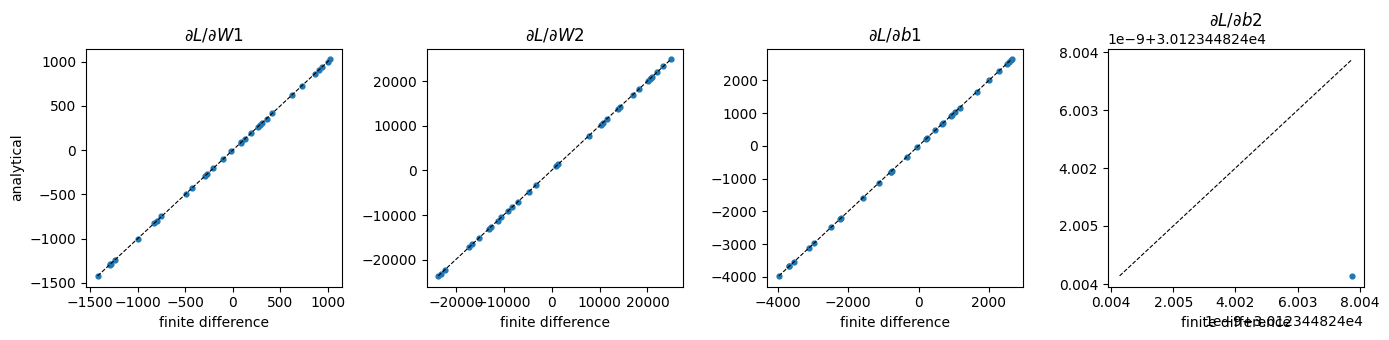

In [18]:
# Plot: analytical vs finite-difference gradient, one panel per parameter. 
# If the gradients agree, all points lie on the diagonal.
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for i, name in enumerate(["W1", "W2", "b1", "b2"]):
    a = np.atleast_1d(analytical[name])
    n = np.atleast_1d(numerical[name])
    ax[i].scatter(n, a, s=12)
    lo = min(a.min(), n.min())
    hi = max(a.max(), n.max())
    ax[i].plot([lo, hi], [lo, hi], "k--", linewidth=0.8)
    ax[i].set_xlabel("finite difference")
    ax[i].set_title(rf"$\partial L / \partial {name}$")
ax[0].set_ylabel("analytical")
plt.tight_layout()
plt.show()

# Task 2.5

In [19]:
# parameters
n_hidden_25 = 128          # (number of hidden neurons)
seed_25 = 10               # (random seed; the same initialisation is used for both runs)
lr_25 = 1e-3               # (learning rate for torch Adam)
n_steps_25 = 50000          # (number of training steps)
log_every = 10             # store the loss terms every log_every steps

# weak and strong regularisation
lam_phys_weak = 1e-6
lam_ic_weak = 1.0
lam_phys_strong = 1e-4
lam_ic_strong = 1.0

In [20]:
def train_pinn(lam_phys, lam_ic, n_hidden, seed, lr, n_steps, t_data, x_data, t_phys, log_every):
    #randon inital weights
    w1, b1, w2, b2 = init_weights(n_hidden, seed)

    # store them as torch tensors so torch Adam can update them
    params = [torch.tensor(p, dtype=torch.float64, requires_grad=True) for p in [w1, b1, w2, np.array([b2])]]
    optimizer = torch.optim.Adam(params, lr=lr)

    history = {"step" : [], "L_data" : [], "L_phys" : [], "L_ic": []}


    for step in range(1, n_steps + 1):
        # current weights as numpy arrays
        w1, b1, w2, b2 = [p.detach().numpy() for p in params]
        b2 = b2[0]

        #analytical grads form 2.3
        g_w1 = grad_W1(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
        g_b1 = grad_b1(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
        g_w2 = grad_W2(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
        g_b2 = grad_b2(w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys, lam_ic)
        grads = [g_w1, g_b1, g_w2, np.array([g_b2])]

        if step == 1 or step % log_every == 0:
            L_data, L_phys, L_ic = loss_terms(w1, b1, w2, b2, t_data, x_data, t_phys)
            history["step"].append(step)
            history["L_data"].append(L_data)
            history["L_phys"].append(L_phys)
            history["L_ic"].append(L_ic)

        # parameter update: give our gradients to torch Adam and take one step
        for i in range(len(params)):
            params[i].grad = torch.tensor(grads[i], dtype=torch.float64)
        optimizer.step()

    w1, b1, w2, b2 = [p.detach().numpy().copy() for p in params]
    final_weights = (w1, b1, w2, b2[0])
    return final_weights, history

In [21]:
weights_weak, history_weak = train_pinn(lam_phys_weak, lam_ic_weak, n_hidden_25, seed_25, lr_25, n_steps_25,
                                        t_data, x_data, t_phys, log_every)

weights_strong, history_strong = train_pinn(lam_phys_strong, lam_ic_strong, n_hidden_25, seed_25, lr_25, n_steps_25,
                                            t_data, x_data, t_phys, log_every)

# final (unweighted) loss terms
for name, history in [("weak", history_weak), ("strong", history_strong)]:
    print(f"{name:6s} | L_data {history['L_data'][-1]:.3e} | L_phys {history['L_phys'][-1]:.3e}"
          f" | L_IC {history['L_ic'][-1]:.3e}")

weak   | L_data 6.088e-05 | L_phys 4.821e+02 | L_IC 6.245e-08
strong | L_data 4.526e-03 | L_phys 3.265e+02 | L_IC 3.871e-04


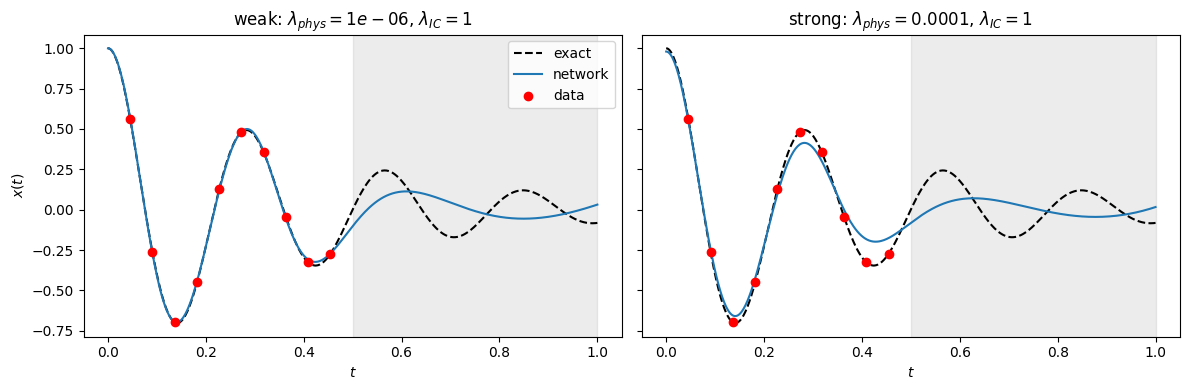

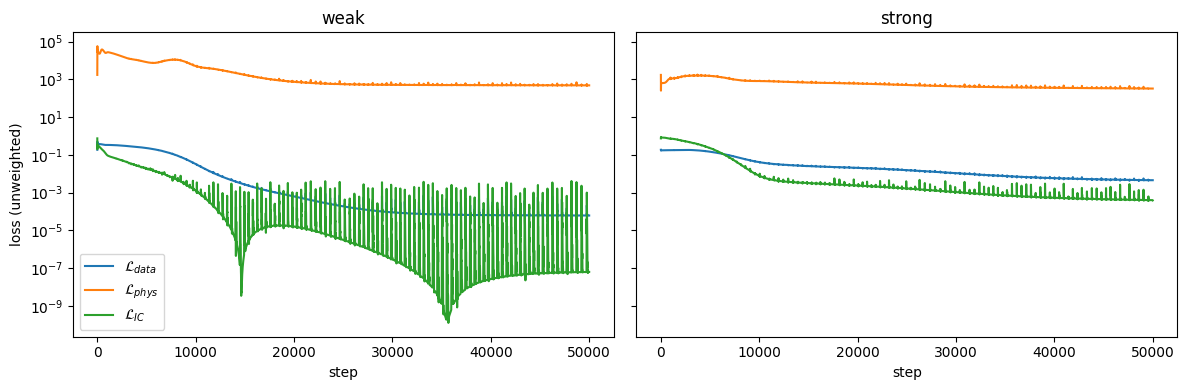

In [22]:
runs = [
    ("weak", weights_weak, history_weak, lam_phys_weak, lam_ic_weak),
    ("strong", weights_strong, history_strong, lam_phys_strong, lam_ic_strong),
]

# ---- inference on (0, 1) ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i in range(len(runs)):
    name, weights, history, lp, li = runs[i]
    w1, b1, w2, b2 = weights
    ax[i].plot(t_plot, x_exact(t_plot), "k--", label="exact")
    ax[i].plot(t_plot, network_output(t_plot, w1, b1, w2, b2), label="network")
    ax[i].scatter(t_data, x_data, color="red", zorder=3, label="data")
    ax[i].axvspan(0.5, 1.0, color="gray", alpha=0.15)
    ax[i].set_title(rf"{name}: $\lambda_{{phys}}={lp:g}$, $\lambda_{{IC}}={li:g}$")
    ax[i].set_xlabel("$t$")
ax[0].set_ylabel("$x(t)$")
ax[0].legend()
plt.tight_layout()
plt.show()

# ---- loss curves (each term separately, unweighted) ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i in range(len(runs)):
    name, weights, history, lp, li = runs[i]
    ax[i].semilogy(history["step"], history["L_data"], label=r"$\mathcal{L}_{data}$")
    ax[i].semilogy(history["step"], history["L_phys"], label=r"$\mathcal{L}_{phys}$")
    ax[i].semilogy(history["step"], history["L_ic"], label=r"$\mathcal{L}_{IC}$")
    ax[i].set_title(name)
    ax[i].set_xlabel("step")
ax[0].set_ylabel("loss (unweighted)")
ax[0].legend()
plt.tight_layout()
plt.show()

### Choosing the loss weights $\lambda_{phys}$ and $\lambda_{IC}$

The three loss terms are

$$
\mathcal{L}_{data} = \frac{1}{N_d}\sum_{i=1}^{N_d}\big(N(t_i) - x_i\big)^2, \qquad
\mathcal{L}_{phys} = \frac{1}{N_c}\sum_{c=1}^{N_c} r(t_c)^2, \qquad
\mathcal{L}_{IC} = \big(N(0) - 1\big)^2 + N'(0)^2,
$$

with the physics residual

$$
r(t) = N''(t) + \mu N'(t) + k N(t), \qquad \mu = 5,\; k = 500 .
$$

**The residual is dominated by $kN$.** The residual plot of the untrained network shows that $N''$ and $\mu N'$ are close to zero, while $kN$ lies on top of $r$. A randomly initialised tanh network is smooth and slowly varying, so its derivatives are small. $N$ itself is not small, and it is multiplied by $k = 500$, while $N'$ is only multiplied by $\mu = 5$. Hence

$$
r(t) \approx k\,N(t).
$$

**The same error costs a factor $k^2$ more in $\mathcal{L}_{phys}$.** Each loss is the mean of a squared difference. Let $\Delta$ denote the typical size of the error the network makes, i.e. how far $N$ is from where it should be.

- *Data:* the difference inside $\mathcal{L}_{data}$ is $N(t_i) - x_i \approx \Delta$, so
$$\mathcal{L}_{data} = \text{mean}\big((N(t_i) - x_i)^2\big) \approx \Delta^2 .$$
- *Initial condition:* the difference inside $\mathcal{L}_{IC}$ is $N(0) - 1 \approx \Delta$, so
$$\mathcal{L}_{IC} \approx \Delta^2 .$$
- *Physics:* the quantity inside $\mathcal{L}_{phys}$ is the residual $r$, which is zero for the exact solution. Since $r \approx kN$, an error of $\Delta$ in $N$ shows up as an error of about $k\Delta$ in $r$, so
$$\mathcal{L}_{phys} = \text{mean}(r^2) \approx (k\Delta)^2 = k^2\Delta^2 .$$

Thus the same error $\Delta$ is penalised $k^2 = 250\,000$ times more strongly by $\mathcal{L}_{phys}$ than by $\mathcal{L}_{data}$ or $\mathcal{L}_{IC}$.

**Equal weighting.** We want an error of size $\Delta$ to contribute equally to the total loss $\mathcal{L} = \mathcal{L}_{data} + \lambda_{phys}\mathcal{L}_{phys} + \lambda_{IC}\mathcal{L}_{IC}$ through every term:

$$
\mathcal{L}_{data} = \lambda_{IC}\,\mathcal{L}_{IC} = \lambda_{phys}\,\mathcal{L}_{phys}
\quad\Longrightarrow\quad
\Delta^2 = \lambda_{IC}\,\Delta^2 = \lambda_{phys}\,k^2\Delta^2 .
$$

The first equality gives

$$
\lambda_{IC} = 1 ,
$$

and the second gives

$$
\lambda_{phys} = \frac{1}{k^2} = \frac{1}{500^2} = 4\times10^{-6}.
$$

With these values the data, physics and initial-condition terms have the same weight in $\mathcal{L}$. Values of $\lambda_{phys}$ below $1/k^2$ correspond to weak regularisation (the data term dominates), and values above $1/k^2$ to strong regularisation (the physics term dominates).

# Task 2.6

Same training as 2.5 (same initial weights, same $\lambda$'s, same torch Adam), but now the gradients come from `torch.autograd.grad`. The time derivatives $N'$, $N''$ are also computed with autograd.

In [23]:
# parameters (same as 2.5 so the two runs can be compared)
n_hidden_26 = n_hidden_25
seed_26 = seed_25
lr_26 = lr_25
n_steps_26 = n_steps_25

In [24]:
# data, collocation points and t=0 as torch tensors
t_data_t = torch.tensor(t_data, dtype=torch.float64).reshape(-1, 1)
x_data_t = torch.tensor(x_data, dtype=torch.float64)
t_phys_t = torch.tensor(t_phys, dtype=torch.float64).reshape(-1, 1)
t_zero_t = torch.zeros((1, 1), dtype=torch.float64)


def torch_net(t, w1, b1, w2, b2):
    # network output, then N' and N'' with autograd (create_graph so we can differentiate again)
    t = t.clone().requires_grad_(True)
    N = torch.tanh(t * w1 + b1) @ w2 + b2
    dN = torch.autograd.grad(N.sum(), t, create_graph=True)[0]
    ddN = torch.autograd.grad(dN.sum(), t, create_graph=True)[0]
    return N, dN.ravel(), ddN.ravel()


def torch_loss_terms(w1, b1, w2, b2):
    # same three losses as in 2.3, written with torch
    N, dN, ddN = torch_net(t_data_t, w1, b1, w2, b2)
    L_data = torch.mean((N - x_data_t)**2)

    N, dN, ddN = torch_net(t_phys_t, w1, b1, w2, b2)
    r = ddN + mu * dN + k * N
    L_phys = torch.mean(r**2)

    N, dN, ddN = torch_net(t_zero_t, w1, b1, w2, b2)
    L_ic = (N[0] - 1)**2 + dN[0]**2

    return L_data, L_phys, L_ic

### Relative error between hand-derived and autograd gradients at initialisation

In [25]:
w1, b1, w2, b2 = init_weights(n_hidden_26, seed_26)
params = [torch.tensor(p, dtype=torch.float64, requires_grad=True) for p in [w1, b1, w2, np.array([b2])]]
names = ["W1", "b1", "W2", "b2"]

for name, lp, li in [("weak", lam_phys_weak, lam_ic_weak), ("strong", lam_phys_strong, lam_ic_strong)]:
    # hand-derived (2.3)
    args = (w1, b1, w2, b2, t_data, x_data, t_phys, lp, li)
    hand = [grad_W1(*args), grad_b1(*args), grad_W2(*args), np.array([grad_b2(*args)])]

    # autograd
    L_data, L_phys, L_ic = torch_loss_terms(*params)
    auto = torch.autograd.grad(L_data + lp * L_phys + li * L_ic, params)
    auto = [g.numpy() for g in auto]

    print(name)
    for i in range(4):
        print(f"   {names[i]:3s} {relative_error(hand[i], auto[i]):.3e}")
    print(f"   all {relative_error(np.concatenate(hand), np.concatenate(auto)):.3e}")

weak
   W1  2.501e-16
   b1  1.861e-16
   W2  1.775e-16
   b2  0.000e+00
   all 1.750e-16
strong
   W1  5.448e-15
   b1  7.014e-16
   W2  9.419e-16
   b2  7.515e-16
   all 9.355e-16


### Training with autograd gradients

In [26]:
def train_pinn_autograd(lam_phys, lam_ic, n_hidden, seed, lr, n_steps, log_every):
    # same initial weights as in 2.5
    w1, b1, w2, b2 = init_weights(n_hidden, seed)
    params = [torch.tensor(p, dtype=torch.float64, requires_grad=True) for p in [w1, b1, w2, np.array([b2])]]
    optimizer = torch.optim.Adam(params, lr=lr)

    history = {"step" : [], "L_data" : [], "L_phys" : [], "L_ic": []}

    for step in range(1, n_steps + 1):
        # loss and its gradients with autograd
        L_data, L_phys, L_ic = torch_loss_terms(*params)
        L = L_data + lam_phys * L_phys + lam_ic * L_ic
        grads = torch.autograd.grad(L, params)

        if step == 1 or step % log_every == 0:
            history["step"].append(step)
            history["L_data"].append(L_data.item())
            history["L_phys"].append(L_phys.item())
            history["L_ic"].append(L_ic.item())

        # same update as 2.5: give the gradients to torch Adam
        for i in range(len(params)):
            params[i].grad = grads[i]
        optimizer.step()

    w1, b1, w2, b2 = [p.detach().numpy().copy() for p in params]
    return (w1, b1, w2, b2[0]), history

In [27]:
import time

results_26 = {}
for name, lp, li in [("weak", lam_phys_weak, lam_ic_weak), ("strong", lam_phys_strong, lam_ic_strong)]:
    # hand-derived gradients (train_pinn from 2.5)
    start = time.time()
    results_26[("hand", name)] = train_pinn(lp, li, n_hidden_26, seed_26, lr_26, n_steps_26,
                                            t_data, x_data, t_phys, log_every)
    print(f"{name:6s} hand     {time.time() - start:.1f} s")

    # autograd gradients
    start = time.time()
    results_26[("autograd", name)] = train_pinn_autograd(lp, li, n_hidden_26, seed_26, lr_26, n_steps_26, log_every)
    print(f"{name:6s} autograd {time.time() - start:.1f} s")

weak   hand     106.7 s
weak   autograd 120.1 s
strong hand     129.3 s
strong autograd 159.6 s


weak   hand     | L_data 6.088e-05 | L_phys 4.821e+02 | L_IC 6.245e-08
weak   autograd | L_data 6.053e-05 | L_phys 4.813e+02 | L_IC 6.422e-08
weak   max |x_hand - x_autograd| = 3.528e-04
strong hand     | L_data 4.526e-03 | L_phys 3.265e+02 | L_IC 3.871e-04
strong autograd | L_data 4.515e-03 | L_phys 3.266e+02 | L_IC 3.979e-04
strong max |x_hand - x_autograd| = 8.475e-04


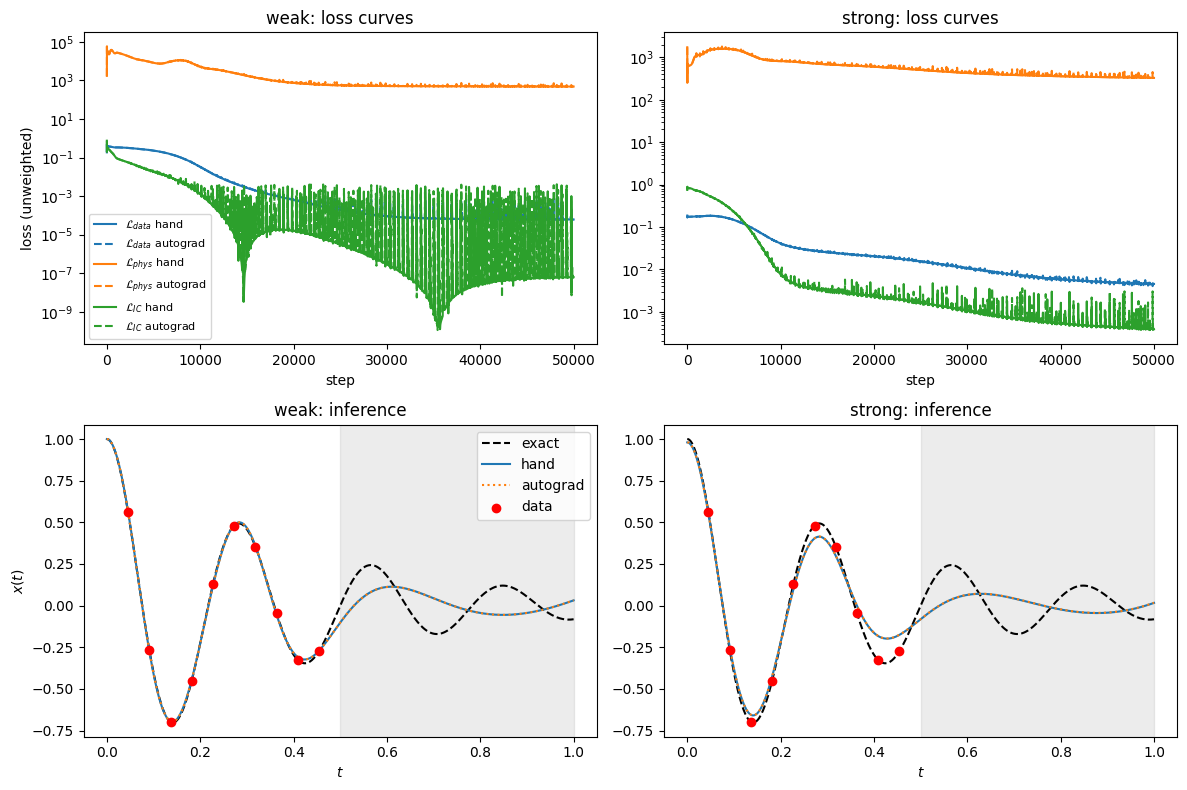

In [28]:
# final losses and difference between the two trained networks
for name in ["weak", "strong"]:
    for method in ["hand", "autograd"]:
        weights, history = results_26[(method, name)]
        print(f"{name:6s} {method:8s} | L_data {history['L_data'][-1]:.3e} | L_phys {history['L_phys'][-1]:.3e}"
              f" | L_IC {history['L_ic'][-1]:.3e}")
    x_hand = network_output(t_plot, *results_26[("hand", name)][0])
    x_auto = network_output(t_plot, *results_26[("autograd", name)][0])
    print(f"{name:6s} max |x_hand - x_autograd| = {np.max(np.abs(x_hand - x_auto)):.3e}")

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j, name in enumerate(["weak", "strong"]):
    w_hand, h_hand = results_26[("hand", name)]
    w_auto, h_auto = results_26[("autograd", name)]

    # loss curves: hand solid, autograd dashed
    for key, label in [("L_data", r"$\mathcal{L}_{data}$"), ("L_phys", r"$\mathcal{L}_{phys}$"), ("L_ic", r"$\mathcal{L}_{IC}$")]:
        line, = ax[0, j].semilogy(h_hand["step"], h_hand[key], label=label + " hand")
        ax[0, j].semilogy(h_auto["step"], h_auto[key], "--", color=line.get_color(), label=label + " autograd")
    ax[0, j].set_title(name + ": loss curves")
    ax[0, j].set_xlabel("step")

    # inference
    ax[1, j].plot(t_plot, x_exact(t_plot), "k--", label="exact")
    ax[1, j].plot(t_plot, network_output(t_plot, *w_hand), label="hand")
    ax[1, j].plot(t_plot, network_output(t_plot, *w_auto), ":", label="autograd")
    ax[1, j].scatter(t_data, x_data, color="red", zorder=3, label="data")
    ax[1, j].axvspan(0.5, 1.0, color="gray", alpha=0.15)
    ax[1, j].set_title(name + ": inference")
    ax[1, j].set_xlabel("$t$")

ax[0, 0].set_ylabel("loss (unweighted)")
ax[1, 0].set_ylabel("$x(t)$")
ax[0, 0].legend(fontsize=8)
ax[1, 0].legend()
plt.tight_layout()
plt.show()

### Structure of the hand-derived gradients

With $N(t) = \sum_{b=1}^{\ell_1} w_b^{(2)}\tanh\big(z_b^{(1)}(t)\big) + b^{(2)}$ and $z_b^{(1)} = w_b^{(1)}t + b_b^{(1)}$, every gradient has the form

$$\frac{\partial \mathcal{L}}{\partial w_b} = \sum_{\text{points}} (\text{error at the point}) \times (\text{sensitivity of the error to } w_b)$$

For each loss term:

$$\frac{\partial \mathcal{L}_{data}}{\partial w_b} = \frac{2}{N_d}\sum_{i=1}^{N_d} \big(N(t_i)-x(t_i)\big)\,\frac{\partial N}{\partial w_b}(t_i)$$

$$\frac{\partial \mathcal{L}_{phys}}{\partial w_b} = \frac{2}{N_p}\sum_{p=1}^{N_p} r_p\left(\frac{\partial N''}{\partial w_b} + \frac{\mu}{m}\frac{\partial N'}{\partial w_b} + \frac{k}{m}\frac{\partial N}{\partial w_b}\right)(t_p)$$

$$\frac{\partial \mathcal{L}_{IC}}{\partial w_b} = 2\big(N(0)-1\big)\frac{\partial N(0)}{\partial w_b} + 2N'(0)\frac{\partial N'(0)}{\partial w_b}$$

where $r_p = N''(t_p) + \frac{\mu}{m}N'(t_p) + \frac{k}{m}N(t_p)$. All sensitivities are built from $\tanh(z_b^{(1)})$, $\operatorname{sech}^2(z_b^{(1)})$, $w_b^{(1)}$, $w_b^{(2)}$ and $t$.

### Why this is useful

1. **Physics gradient $\propto r_p$:** it is zero whenever all $r_p = 0$, including for $N\equiv 0$. The physics term cannot push the network away from the zero solution, which explains the strong-regularisation result.

2. **Factor $k/m$:** the physics gradient contains $\frac{k}{m}\frac{\partial N}{\partial w_b}$, and $r_p \approx \frac{k}{m}N(t_p)$. So it is about $(k/m)^2$ times larger than the data gradient, which is why $\lambda_{phys}\sim (m/k)^2$.

3. **At $t=0$, $w^{(1)}$ does not affect $N(0)$.**
   $$N(0) = \sum_{b=1}^{\ell_1} w_b^{(2)}\tanh\big(b_b^{(1)}\big) + b^{(2)}$$
   contains no $w^{(1)}$, so $\frac{\partial}{\partial w_b^{(1)}}\big(N(0)-1\big)^2 = 0$. In general $\frac{\partial N}{\partial w_b^{(1)}} = w_b^{(2)}\,t\,\operatorname{sech}^2(z_b^{(1)})$, which vanishes at $t=0$ because of the factor $t$ from $\partial z_b^{(1)}/\partial w_b^{(1)} = t$. Only the velocity term is left:
   $$\frac{\partial \mathcal{L}_{IC}}{\partial w_b^{(1)}} = 2N'(0)\,w_b^{(2)}\operatorname{sech}^2\big(b_b^{(1)}\big),$$
   while for the output weights
   $$\frac{\partial \mathcal{L}_{IC}}{\partial w_b^{(2)}} = 2\big(N(0)-1\big)\tanh\big(b_b^{(1)}\big) + 2N'(0)\,w_b^{(1)}\operatorname{sech}^2\big(b_b^{(1)}\big).$$
   So $w^{(1)}$ only helps with $x'(0)=0$. The condition $x(0)=1$ is fixed by $b^{(1)}$, $w^{(2)}$ and $b^{(2)}$.

4. **The physics term grows with powers of $w^{(1)}$.** Each time derivative brings out one more factor $w_b^{(1)}$ (from $\partial z_b^{(1)}/\partial t = w_b^{(1)}$):
   $$N' = \sum_b w_b^{(2)} w_b^{(1)}\operatorname{sech}^2(z_b^{(1)}), \qquad N'' = -2\sum_b w_b^{(2)}\big(w_b^{(1)}\big)^2\tanh(z_b^{(1)})\operatorname{sech}^2(z_b^{(1)}).$$
   The same powers appear in the sensitivities of $N''$:
   $$\frac{\partial N''}{\partial w_b^{(2)}} = -2\big(w_b^{(1)}\big)^2\tanh\operatorname{sech}^2, \qquad \frac{\partial N''}{\partial w_b^{(1)}} = -2w_b^{(2)}w_b^{(1)}\operatorname{sech}^2\Big[t\,w_b^{(1)}\big(1-3\tanh^2\big) + 2\tanh\Big].$$
   $w_b^{(1)}$ sets how fast neuron $b$ changes in time, so fitting an oscillation with $\omega\approx 22$ needs $|w^{(1)}|$ of that order. Then $N''$, $r_p$ and the physics gradient become very large and very sensitive to $w^{(1)}$. The physics loss changes steeply with $w^{(1)}$, which makes training harder.

Autograd gives the same numbers but hides this structure.

# Task 2.7

In [29]:
# parameters (same as 2.5 so the runs can be compared)
n_hidden_27 = n_hidden_25
seed_27 = seed_25
lr_27 = lr_25
n_steps_27 = n_steps_25
lam_phys_weak_27 = lam_phys_weak
lam_phys_strong_27 = lam_phys_strong

In [ ]:

def hard_output(t, w1, b1, w2, b2):
    N = network_output(t, w1, b1, w2, b2)
    return 1 + t**2 * N

def hard_dt(t, w1, b1, w2, b2):

    N = network_output(t, w1, b1, w2, b2)
    dN = network_dt(t, w1, b1, w2, b2)
    return 2 * t * N + t**2 * dN

def hard_dtt(t, w1, b1, w2, b2):
    N = network_output(t, w1, b1, w2, b2)
    dN = network_dt(t, w1, b1, w2, b2)
    ddN = network_dtt(t, w1, b1, w2, b2)
    return 2 * N + 4 * t * dN + t**2 * ddN

def hard_residual(t, w1, b1, w2, b2):
    return hard_dtt(t, w1, b1, w2, b2) + mu * hard_dt(t, w1, b1, w2, b2) + k * hard_output(t, w1, b1, w2, b2)

def hard_loss_terms(w1, b1, w2, b2, t_data, x_data, t_phys):
    # no L_IC anymore
    L_data = np.mean((hard_output(t_data, w1, b1, w2, b2) - x_data)**2)
    L_phys = np.mean(hard_residual(t_phys, w1, b1, w2, b2)**2)
    return L_data, L_phys

In [31]:
# gradients: same chain rule as 2.3, the sensitivities of x~ come from the old ones
def hard_sensitivities(sensitivity_function, t, w1, b1, w2):
    dN, dN1, dN2 = sensitivity_function(t, w1, b1, w2)
    t = np.asarray(t, dtype=np.float64).reshape(-1, 1)
    dX = t**2 * dN                              # d x~   / d theta
    dX1 = 2 * t * dN + t**2 * dN1               # d x~'  / d theta
    dX2 = 2 * dN + 4 * t * dN1 + t**2 * dN2     # d x~'' / d theta
    return dX, dX1, dX2


def hard_gradient(sensitivity_function, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys):
    #data term
    dX_d, dX1_d, dX2_d = hard_sensitivities(sensitivity_function, t_data, w1, b1, w2)
    error_data = hard_output(t_data, w1, b1, w2, b2) - x_data
    grad_data = 2 / len(t_data) * (error_data @ dX_d)

    #physics term
    dX_p, dX1_p, dX2_p = hard_sensitivities(sensitivity_function, t_phys, w1, b1, w2)
    r = hard_residual(t_phys, w1, b1, w2, b2)
    grad_phys = 2 / len(t_phys) * (r @ (dX2_p + mu * dX1_p + k * dX_p))

    #no IC term
    return grad_data + lam_phys * grad_phys

In [33]:
def train_pinn_hard(lam_phys, n_hidden, seed, lr, n_steps, t_data, x_data, t_phys, log_every):
    # same initial weights and same torch Adam as 2.5
    w1, b1, w2, b2 = init_weights(n_hidden, seed)
    params = [torch.tensor(p, dtype=torch.float64, requires_grad=True) for p in [w1, b1, w2, np.array([b2])]]
    optimizer = torch.optim.Adam(params, lr=lr)

    sens = [sensitivities_W1, sensitivities_b1, sensitivities_W2, sensitivities_b2]
    history = {"step" : [], "L_data" : [], "L_phys" : []}

    for step in range(1, n_steps + 1):
        w1, b1, w2, b2 = [p.detach().numpy() for p in params]
        b2 = b2[0]

        # hand-derived gradients for W1, b1, W2, b2
        grads = []
        for f in sens:
            grads.append(hard_gradient(f, w1, b1, w2, b2, t_data, x_data, t_phys, lam_phys))

        if step == 1 or step % log_every == 0:
            L_data, L_phys = hard_loss_terms(w1, b1, w2, b2, t_data, x_data, t_phys)
            history["step"].append(step)
            history["L_data"].append(L_data)
            history["L_phys"].append(L_phys)

        # torch Adam update
        for i in range(len(params)):
            params[i].grad = torch.tensor(grads[i], dtype=torch.float64)
        optimizer.step()

    w1, b1, w2, b2 = [p.detach().numpy().copy() for p in params]
    return (w1, b1, w2, b2[0]), history

In [34]:
weights_weak_hard, history_weak_hard = train_pinn_hard(lam_phys_weak_27, n_hidden_27, seed_27, lr_27, n_steps_27,
                                                       t_data, x_data, t_phys, log_every)

weights_strong_hard, history_strong_hard = train_pinn_hard(lam_phys_strong_27, n_hidden_27, seed_27, lr_27, n_steps_27,
                                                           t_data, x_data, t_phys, log_every)

for name, history in [("weak", history_weak_hard), ("strong", history_strong_hard)]:
    print(f"{name:6s} hard | L_data {history['L_data'][-1]:.3e} | L_phys {history['L_phys'][-1]:.3e}")

weak   hard | L_data 1.240e-06 | L_phys 1.207e+02
strong hard | L_data 2.456e-03 | L_phys 2.580e+02


weak
   soft | |x(0)-1| 2.499e-04 | |x'(0)| 4.346e-07 | MSE on (0.5,1) 1.714e-02
   hard | |x(0)-1| 0.000e+00 | |x'(0)| 0.000e+00 | MSE on (0.5,1) 6.043e-03
strong
   soft | |x(0)-1| 2.031e-02 | |x'(0)| 1.402e-03 | MSE on (0.5,1) 1.790e-02
   hard | |x(0)-1| 0.000e+00 | |x'(0)| 0.000e+00 | MSE on (0.5,1) 1.165e-02


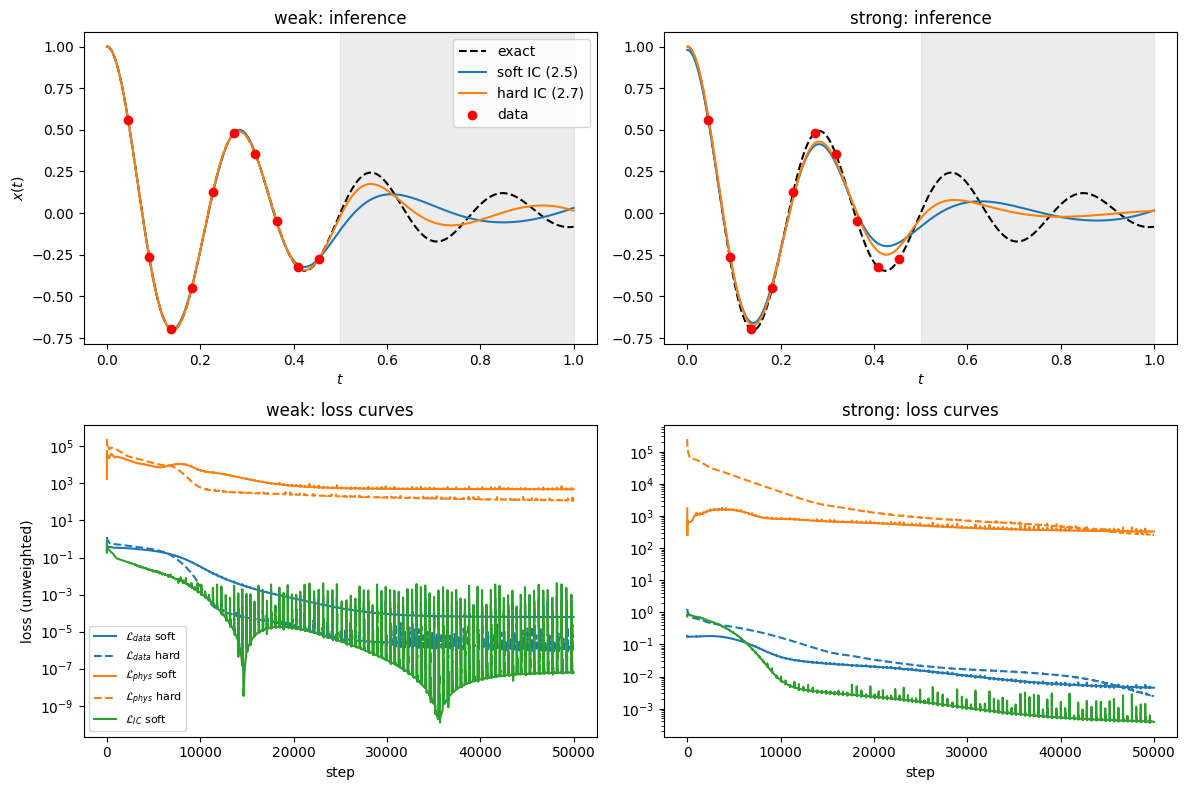

In [35]:
# (2.5) vs hard (2.7)
runs_27 = [
    ("weak", weights_weak, history_weak, weights_weak_hard, history_weak_hard),
    ("strong", weights_strong, history_strong, weights_strong_hard, history_strong_hard),
]
late = t_plot > 0.5     # the interval (0.5, 1)

for name, w_soft, h_soft, w_hard, h_hard in runs_27:
    # initial conditions
    ic_x_soft = abs(network_output(0.0, *w_soft)[0] - 1)
    ic_v_soft = abs(network_dt(0.0, *w_soft)[0])
    ic_x_hard = abs(hard_output(0.0, *w_hard)[0] - 1)
    ic_v_hard = abs(hard_dt(0.0, *w_hard)[0])

    # error on (0.5, 1)
    mse_soft = np.mean((network_output(t_plot[late], *w_soft) - x_exact(t_plot[late]))**2)
    mse_hard = np.mean((hard_output(t_plot[late], *w_hard) - x_exact(t_plot[late]))**2)

    print(name)
    print(f"   soft | |x(0)-1| {ic_x_soft:.3e} | |x'(0)| {ic_v_soft:.3e} | MSE on (0.5,1) {mse_soft:.3e}")
    print(f"   hard | |x(0)-1| {ic_x_hard:.3e} | |x'(0)| {ic_v_hard:.3e} | MSE on (0.5,1) {mse_hard:.3e}")

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j in range(len(runs_27)):
    name, w_soft, h_soft, w_hard, h_hard = runs_27[j]

    # inference
    ax[0, j].plot(t_plot, x_exact(t_plot), "k--", label="exact")
    ax[0, j].plot(t_plot, network_output(t_plot, *w_soft), label="soft IC (2.5)")
    ax[0, j].plot(t_plot, hard_output(t_plot, *w_hard), label="hard IC (2.7)")
    ax[0, j].scatter(t_data, x_data, color="red", zorder=3, label="data")
    ax[0, j].axvspan(0.5, 1.0, color="gray", alpha=0.15)
    ax[0, j].set_title(name + ": inference")
    ax[0, j].set_xlabel("$t$")

    # loss curves: soft solid, hard dashed
    l1, = ax[1, j].semilogy(h_soft["step"], h_soft["L_data"], label=r"$\mathcal{L}_{data}$ soft")
    ax[1, j].semilogy(h_hard["step"], h_hard["L_data"], "--", color=l1.get_color(), label=r"$\mathcal{L}_{data}$ hard")
    l2, = ax[1, j].semilogy(h_soft["step"], h_soft["L_phys"], label=r"$\mathcal{L}_{phys}$ soft")
    ax[1, j].semilogy(h_hard["step"], h_hard["L_phys"], "--", color=l2.get_color(), label=r"$\mathcal{L}_{phys}$ hard")
    ax[1, j].semilogy(h_soft["step"], h_soft["L_ic"], label=r"$\mathcal{L}_{IC}$ soft")
    ax[1, j].set_title(name + ": loss curves")
    ax[1, j].set_xlabel("step")

ax[0, 0].set_ylabel("$x(t)$")
ax[1, 0].set_ylabel("loss (unweighted)")
ax[0, 0].legend()
ax[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

hard enforcement:
- condition is knonw exaclty and is simple to build
- want fewwer hyperparameters
- errors at t = 0 would spread out of ocntrol
- removes trivial solutions (such as x = 0)


soft enforcement:
- uncertanty in initial conditions 
- a lot of conditions (boudary etc) that its hard to finda  trick that works
- flexibility ? 